# RQ1 Feature Search: Which features really help predict the dollar amount paid?

**RQ1:** Can we predict the dollar amount paid on a building claim using flood-zone, construction, policy and geographic features?

In notebook 04 we used 15 features chosen in notebook 03. Here we look at **every pre-loss feature in the data**,
measure how much each one adds to the **dollar** prediction, try many combinations, and then explain what the best model learned.

**Rules that keep the search honest**
1. Only facts known **when a claim is reported**. Payments, damage, values set by the adjuster, water depth and cause of damage are never used.
2. Features are chosen with **cross validation on the training part only**. The test part is used **once**, at the end.
   (If we picked the combination that is best on the test part, the score would look better only because we chose it there.)
3. We search in **two settings**:
   - **A. Known storms:** random 70/30 split of all years (the main setting of the regional notebooks).
   - **B. New storms:** while choosing, every fold holds out one whole year; the final test is 2024-2025.
4. One model for everything: **gradient boosting with Poisson loss, trained on dollars**. Score: **R² in dollars**.

---
# Section 0: Setup and the feature groups

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, GroupKFold, train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.inspection import permutation_importance
import warnings; warnings.filterwarnings('ignore')
SEED = 42
pd.set_option('display.max_columns', 60)

work = pd.read_parquet('outputs/nfip_claims_simple_clean.parquet')
keys = pd.read_parquet('outputs/nfip_claims_simple_keys.parquet')
raw = pd.read_parquet('/Users/home/workspace/School/DataMining/project/NfipClaimsV3.parquet',
                      columns=['id', 'baseFloodElevation', 'lowestFloorElevation', 'floodZoneCurrent', 'yearOfLoss'])
raw = raw[raw['yearOfLoss'].between(2020, 2025)].drop(columns='yearOfLoss')
extra = keys[['id', 'countyCode']].merge(raw, on='id', how='left')      # same row order as work
for c in ['countyCode', 'baseFloodElevation', 'lowestFloorElevation', 'floodZoneCurrent']:
    work[c] = extra[c].values
for c in ['baseFloodElevation', 'lowestFloorElevation']:
    work[c] = work[c].astype(float)
    work.loc[work[c].abs() >= 9000, c] = np.nan                         # 9990 / 9999 placeholders

paid = work[work['is_paid'] == 1].copy()
paid['year'] = paid['dateOfLoss'].dt.year
paid['occupancyType'] = paid['occupancyType'].replace({1: 11, 2: 12, 3: 13, 4: 18, 6: 18})   # legacy codes
print(f'Paid claims: {len(paid):,}')

Paid claims: 212,932


In [2]:
def zone_family(z):
    z = str(z).upper()
    if z in ['X', 'B', 'C']: return 'X'
    if z.startswith('V'): return 'V'
    if z in ['AE', 'AH', 'AO', 'A99', 'A']: return z
    if z.startswith('A'): return 'AE'
    return 'other'
DED = {'0': 500, '1': 1000, '2': 2000, '3': 3000, '4': 4000, '5': 5000, '9': 750, 'A': 10000, 'B': 15000, 'C': 20000,
       'D': 25000, 'E': 50000, 'F': 1250, 'G': 1500, 'H': 200}
F = pd.DataFrame(index=paid.index)
F['bldg_coverage'] = paid['totalBuildingInsuranceCoverage']
F['contents_coverage'] = paid['totalContentsInsuranceCoverage']
F['bldg_deductible'] = paid['bldg_deductible_usd']
F['contents_deductible'] = paid['contentsDeductibleCode'].map(DED).fillna(0)
F['policy_count'] = paid['policyCount']
F['units'] = paid['numberOfUnits']
F['building_age'] = paid['building_age']
F['post_firm'] = paid['postFIRMConstructionIndicator']
F['policy_tenure'] = (paid['dateOfLoss'] - paid['originalNBDate']).dt.days / 365.25
F['elevated'] = paid['elevatedBuildingIndicator']
F['elevation_difference'] = paid['elevationDifference']            # blanks kept: boosting can handle them
F['base_flood_elevation'] = paid['baseFloodElevation']
F['lowest_floor_elevation'] = paid['lowestFloorElevation']
F['has_elevation_data'] = paid['elevationDifference'].notna().astype(int)
F['crs_class'] = paid['crsClassCode']
F['crs_unknown'] = paid['crsClassCode_missing']
F['risk_rating_2'] = (paid['rateMethod'] == 'RE').astype(int)
F['primary_residence'] = paid['primaryResidenceIndicator']
F['rental'] = paid['rentalPropertyIndicator']
F['small_business'] = paid['smallBusinessIndicatorBuilding']
F['latitude'] = paid['latitude']; F['longitude'] = paid['longitude']
F['loss_month'] = paid['loss_month']
F['loss_year'] = paid['year']
F['report_lag'] = paid['report_lag_days']
F['named_storm'] = paid['is_named_event']
county_share = paid['countyCode'].map(paid['countyCode'].value_counts(normalize=True))   # how common the county is (no target)
F['county_frequency'] = county_share.fillna(0)

ONE_HOT = {'occupancy': paid['occupancyType'].astype(str), 'condo_type': paid['condominiumCoverageTypeCode'].astype(str),
           'building_use': paid['buildingDescriptionCode'].astype(str), 'foundation': paid['foundationType'].astype(str),
           'basement': paid['basementEnclosureCrawlspaceType'].astype(str), 'obstruction': paid['obstructionType'].astype(str),
           'floors': paid['numberOfFloorsInTheInsuredBuilding'].astype(str), 'contents_location': paid['locationOfContents'].astype(str),
           'zone_rated': paid['flood_zone_family'], 'zone_current': paid['floodZoneCurrent'].map(zone_family).fillna('none'),
           'state': paid['state_group']}
for name, col in ONE_HOT.items():
    d = pd.get_dummies(col, prefix=name, dtype=int)
    F = pd.concat([F, d.loc[:, d.mean() >= 0.002]], axis=1)          # drop very rare levels
def cols(*prefixes):
    return [c for c in F.columns if any(c == p or c.startswith(p + '_') for p in prefixes)]

GROUPS = {
    'coverage':          cols('bldg_coverage', 'contents_coverage'),
    'deductibles':       cols('bldg_deductible', 'contents_deductible'),
    'size & occupancy':  cols('policy_count', 'units', 'occupancy', 'condo_type'),
    'use':               cols('primary_residence', 'rental', 'small_business', 'building_use'),
    'construction':      cols('foundation', 'basement', 'elevated', 'obstruction', 'floors', 'contents_location'),
    'age':               cols('building_age', 'post_firm', 'policy_tenure'),
    'flood zone':        cols('zone_rated', 'zone_current'),
    'elevation data':    cols('elevation_difference', 'base_flood_elevation', 'lowest_floor_elevation', 'has_elevation_data'),
    'community / rating': cols('crs_class', 'crs_unknown', 'risk_rating_2'),
    'state':             cols('state'),
    'coordinates':       cols('latitude', 'longitude'),
    'county':            cols('county_frequency') + ['county_history'],
    'timing':            cols('loss_month', 'loss_year', 'report_lag'),
    'storm':             cols('named_storm') + ['storm_history'],
}
summary = pd.DataFrame({'features': [len(v) for v in GROUPS.values()], 'examples': [', '.join(v[:4]) for v in GROUPS.values()]},
                       index=GROUPS.keys())
print(f'Candidate features: {F.shape[1] + 2} in {len(GROUPS)} groups')
summary

Candidate features: 106 in 14 groups


,features,examples
coverage,2,"bldg_coverage, contents_coverage"
deductibles,2,"bldg_deductible, contents_deductible"
size & occupancy,13,"policy_count, units, occupancy_11.0, occupancy..."
use,10,"primary_residence, rental, small_business, bui..."
construction,34,"elevated, foundation_0, foundation_1, foundati..."
age,3,"building_age, post_firm, policy_tenure"
flood zone,15,"zone_rated_A, zone_rated_A99, zone_rated_AE, z..."
elevation data,4,"elevation_difference, base_flood_elevation, lo..."
community / rating,3,"crs_class, crs_unknown, risk_rating_2"
state,11,"state_AL, state_FL, state_KY, state_LA"


**Two "history" features** are made inside every fold, from that fold's training rows only:
- `county_history`: the average log payment of earlier claims in the same county (pulled toward the overall average when the county has few claims)
- `storm_history`: the same, for claims from the same named storm. The storm name is known when a claim is reported.
  For a brand-new storm there is no history, so it falls back to the overall average.

In [3]:
y = paid['amountPaidOnBuildingClaim']
ylog = np.log1p(y)

def history(key, tr_idx, all_idx, k=30):
    g = pd.DataFrame({'k': key.loc[tr_idx], 'y': ylog.loc[tr_idx]}).groupby('k')['y'].agg(['mean', 'size'])
    glob = ylog.loc[tr_idx].mean()
    enc = (g['mean'] * g['size'] + glob * k) / (g['size'] + k)
    return key.loc[all_idx].map(enc).fillna(glob).values

def design(groups, tr_idx, te_idx):
    use = [c for g in groups for c in GROUPS[g] if c not in ('county_history', 'storm_history')]
    Xtr, Xte = F.loc[tr_idx, use].copy(), F.loc[te_idx, use].copy()
    if 'county' in groups:
        Xtr['county_history'] = history(paid['countyCode'], tr_idx, tr_idx); Xte['county_history'] = history(paid['countyCode'], tr_idx, te_idx)
    if 'storm' in groups:
        storm = paid['floodEvent'].where(paid['floodEvent'] != 'no_named_event', 'none')
        Xtr['storm_history'] = history(storm, tr_idx, tr_idx); Xte['storm_history'] = history(storm, tr_idx, te_idx)
    return Xtr, Xte

def model():
    return HistGradientBoostingRegressor(loss='poisson', max_iter=200, learning_rate=0.08, max_leaf_nodes=31, random_state=SEED)

def cv_score(groups, setting):
    # mean R2 in dollars over the folds of the training part
    idx = SEL[setting]
    splits = KFold(3, shuffle=True, random_state=SEED).split(idx) if setting == 'A' else GroupKFold(4).split(idx, groups=paid.loc[idx, 'year'])
    out = []
    for a, b in splits:
        tr_i, te_i = idx[a], idx[b]
        Xa, Xb = design(groups, tr_i, te_i)
        out.append(r2_score(y.loc[te_i], model().fit(Xa, y.loc[tr_i]).predict(Xb)))
    return float(np.mean(out))

# Setting A: random 70/30 over all years.  Setting B: train 2020-2023, test 2024-2025
A_train, A_test = train_test_split(paid.index, test_size=0.3, random_state=SEED)
B_train, B_test = paid.index[paid['year'] <= 2023], paid.index[paid['year'] >= 2024]
rng = np.random.default_rng(SEED)
SEL = {'A': pd.Index(rng.choice(A_train, 40000, replace=False)),          # samples keep the search fast
       'B': pd.Index(rng.choice(B_train, 40000, replace=False))}
print(f'Setting A: train {len(A_train):,} / test {len(A_test):,}   Setting B: train {len(B_train):,} / test {len(B_test):,}')
print('Search uses 40,000-claim samples of each training part; setting B folds = one loss year each (2020, 2021, 2022, 2023)')

Setting A: train 149,052 / test 63,880   Setting B: train 119,746 / test 93,186
Search uses 40,000-claim samples of each training part; setting B folds = one loss year each (2020, 2021, 2022, 2023)


---
# Section 1: What is each group worth on its own?

In [4]:
ALL = list(GROUPS)
single = pd.DataFrame({s: {g: cv_score([g], s) for g in ALL} for s in ['A', 'B']})
single.columns = ['alone, known storms (A)', 'alone, new storms (B)']
single = single.sort_values('alone, known storms (A)', ascending=False)
single.round(3)

,"alone, known storms (A)","alone, new storms (B)"
coverage,0.199,-0.531
size & occupancy,0.153,-0.634
construction,0.095,-0.595
coordinates,0.082,-0.082
timing,0.066,-0.086
county,0.062,-0.081
storm,0.060,-0.062
deductibles,0.059,-0.190
state,0.040,-0.167
community / rating,0.029,-0.142


---
# Section 2: What do we lose when we remove one group from the full set?

In [5]:
full = {s: cv_score(ALL, s) for s in ['A', 'B']}
drop = pd.DataFrame({s: {g: full[s] - cv_score([x for x in ALL if x != g], s) for g in ALL} for s in ['A', 'B']})
drop.columns = ['loss when removed (A)', 'loss when removed (B)']
print(f"All 14 groups: CV R2 dollars  A = {full['A']:.3f}   B = {full['B']:.3f}")
print('Positive = the group helps; negative = the model is better without it')
drop.sort_values('loss when removed (A)', ascending=False).round(3)

All 14 groups: CV R2 dollars  A = 0.490   B = 0.035
Positive = the group helps; negative = the model is better without it


,loss when removed (A),loss when removed (B)
storm,0.101,0.042
use,0.051,-0.023
coverage,0.048,-0.031
deductibles,0.037,-0.037
coordinates,0.026,0.013
state,0.022,-0.013
elevation data,0.013,0.027
size & occupancy,0.010,0.026
timing,0.008,0.027
community / rating,0.006,0.002


---
# Section 3: Forward selection: build the best combination step by step

Start with nothing. At each step, try adding every remaining group and keep the one that raises the CV score most.
Stop when no group adds at least **0.005** R² (a smaller gain is within the noise of the folds).

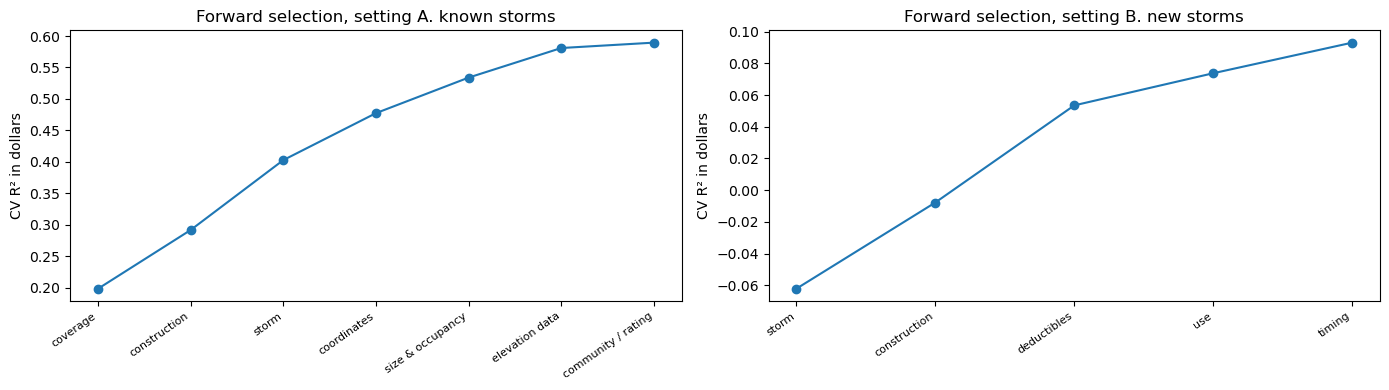

Chosen for A: ['coverage', 'construction', 'storm', 'coordinates', 'size & occupancy', 'elevation data', 'community / rating']
Chosen for B: ['storm', 'construction', 'deductibles', 'use', 'timing']


In [6]:
def forward(setting, min_gain=0.005):
    chosen, best, path = [], -np.inf, []
    while True:
        trials = {g: cv_score(chosen + [g], setting) for g in ALL if g not in chosen}
        g, s = max(trials.items(), key=lambda kv: kv[1])
        if s - best < min_gain and chosen:
            break
        chosen.append(g); best = s; path.append((g, s))
        if len(chosen) == len(ALL): break
    return chosen, path

chosen_A, path_A = forward('A')
chosen_B, path_B = forward('B')
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, path, name in [(ax[0], path_A, 'A. known storms'), (ax[1], path_B, 'B. new storms')]:
    a.plot(range(1, len(path) + 1), [p[1] for p in path], 'o-')
    a.set_xticks(range(1, len(path) + 1)); a.set_xticklabels([p[0] for p in path], rotation=35, ha='right', fontsize=8)
    a.set_ylabel('CV R² in dollars'); a.set_title(f'Forward selection, setting {name}')
plt.tight_layout(); plt.show()
print('Chosen for A:', chosen_A); print('Chosen for B:', chosen_B)

---
# Section 4: The final test (used once)

We compare, on each setting's untouched test part:
1. the **15 features from notebook 03** (what notebooks 04 and the regional notebooks used)
2. **all 14 groups**
3. the **combination chosen by forward selection** in that setting

In [7]:
import json
with open('outputs/simple_feature_lists.json') as f:
    FL = json.load(f)
X_old = pd.get_dummies(work[FL['NOMINAL_FEATURES'] + FL['NUMERIC_FEATURES']], columns=FL['NOMINAL_FEATURES'], dtype=int).loc[paid.index, FL['RQ1']]

def final(setting, groups=None):
    tr, te = (A_train, A_test) if setting == 'A' else (B_train, B_test)
    if groups is None:
        Xa, Xb = X_old.loc[tr], X_old.loc[te]
    else:
        Xa, Xb = design(groups, tr, te)
    m = HistGradientBoostingRegressor(loss='poisson', max_iter=400, learning_rate=0.05, max_leaf_nodes=31, random_state=SEED).fit(Xa, y.loc[tr])
    p = m.predict(Xb)
    return m, Xb, p, {'R2 dollars': r2_score(y.loc[te], p), 'median error $': np.median(np.abs(y.loc[te] - p)),
                      'mean error $': mean_absolute_error(y.loc[te], p), 'features': Xb.shape[1]}

rows, store = [], {}
for s, chosen in [('A', chosen_A), ('B', chosen_B)]:
    for label, groups in [('15 features (notebook 03)', None), ('all 14 groups', ALL), ('forward selection', chosen)]:
        m, Xb, p, r = final(s, groups)
        rows.append({'setting': 'A. known storms' if s == 'A' else 'B. new storms (2024-25)', 'features used': label, **r})
        store[(s, label)] = (m, Xb, p)
results = pd.DataFrame(rows)
results.style.format({'R2 dollars': '{:.3f}', 'median error $': '${:,.0f}', 'mean error $': '${:,.0f}'}).hide(axis='index')

setting,features used,R2 dollars,median error $,mean error $,features
A. known storms,15 features (notebook 03),0.566,"$23,430","$41,401",15
A. known storms,all 14 groups,0.649,"$22,462","$39,601",106
A. known storms,forward selection,0.638,"$24,221","$41,869",60
B. new storms (2024-25),15 features (notebook 03),-0.059,"$30,378","$57,036",15
B. new storms (2024-25),all 14 groups,-0.370,"$29,933","$57,914",106
B. new storms (2024-25),forward selection,0.083,"$32,375","$58,012",51


---
# Section 5: Reverse engineering: what did the best model learn?

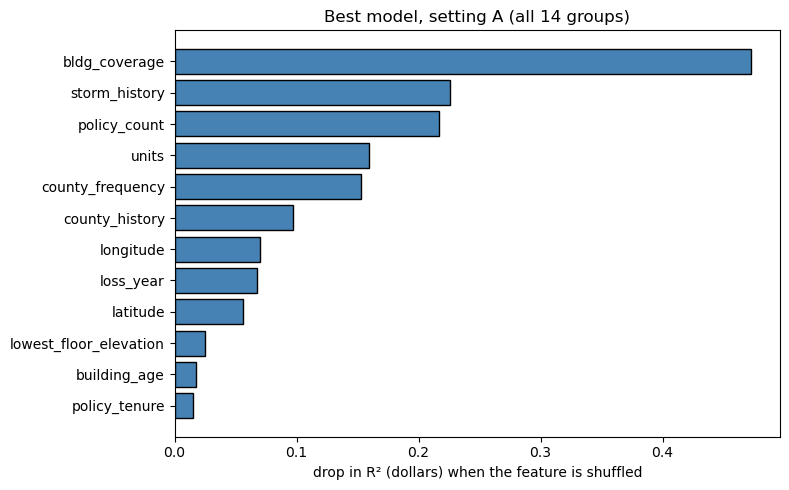

bldg_coverage             0.473
storm_history             0.226
policy_count              0.217
units                     0.159
county_frequency          0.153
county_history            0.097
longitude                 0.070
loss_year                 0.067
latitude                  0.056
lowest_floor_elevation    0.025
building_age              0.017
policy_tenure             0.015


In [8]:
best_A = max([r for r in rows if r['setting'].startswith('A')], key=lambda r: r['R2 dollars'])
m, Xb, p = store[('A', best_A['features used'])]
te = A_test
sub = np.random.default_rng(SEED).choice(len(Xb), min(8000, len(Xb)), replace=False)
pi = permutation_importance(m, Xb.iloc[sub], y.loc[te].iloc[sub], scoring='r2', n_repeats=3, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=Xb.columns).sort_values(ascending=False).head(12)
plt.figure(figsize=(8, 5))
plt.barh(imp.index[::-1], imp.values[::-1], color='steelblue', edgecolor='black')
plt.xlabel('drop in R² (dollars) when the feature is shuffled'); plt.title(f"Best model, setting A ({best_A['features used']})")
plt.tight_layout(); plt.show()
print(imp.round(3).to_string())

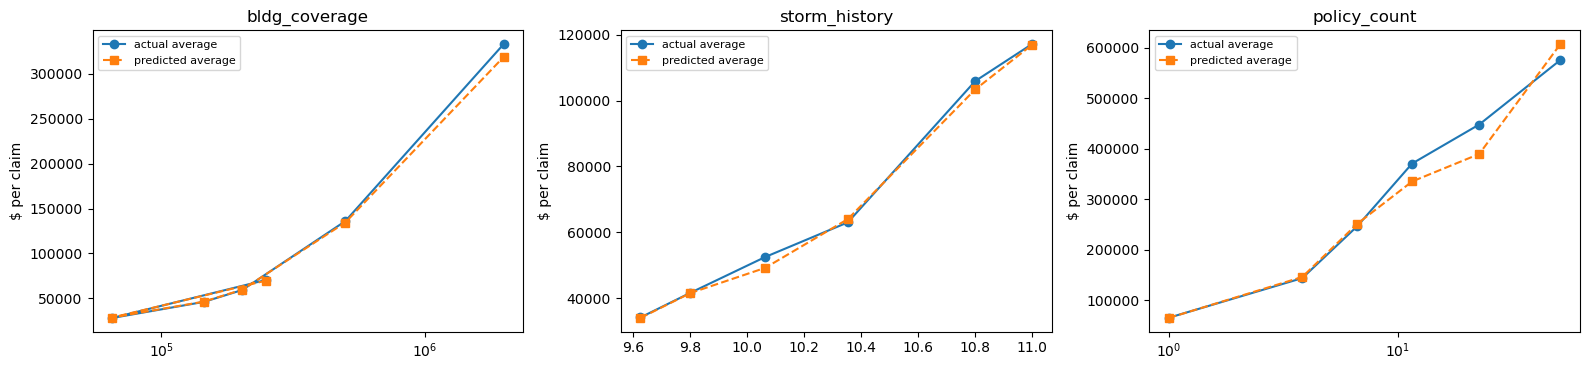

In [9]:
# How does the predicted payment change with the three most important features? (average over the test claims)
top3 = imp.index[:3]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, f in zip(ax, top3):
    x = Xb[f]
    if x.nunique() <= 10:
        bins = x
    elif (x == x.mode()[0]).mean() >= 0.5:       # one value covers most claims (e.g. 1 policy): own bin, split the rest
        rest = x[x != x.mode()[0]]
        edges = np.unique(np.quantile(rest, [0, .25, .5, .75, .9, 1]))
        bins = (pd.cut(x, edges, include_lowest=True, labels=False) + 1).where(x != x.mode()[0], 0)
    else:
        edges = np.unique(np.quantile(x.dropna(), np.linspace(0, 1, 11)))
        bins = pd.cut(x, edges, include_lowest=True, labels=False)
    d = pd.DataFrame({'bin': bins.values, 'x': x.values, 'pred': p, 'true': y.loc[te].values}).groupby('bin').agg(
        x=('x', 'median'), predicted=('pred', 'mean'), actual=('true', 'mean'))
    a.plot(d['x'], d['actual'], 'o-', label='actual average'); a.plot(d['x'], d['predicted'], 's--', label='predicted average')
    a.set_title(f); a.set_ylabel('$ per claim'); a.legend(fontsize=8)
    if x.min() >= 0 and x.max() / max(x.median(), 1) > 50: a.set_xscale('symlog')
plt.tight_layout(); plt.show()

---
# Section 6: What we found

### 1. Yes, more features help, but only for storms the model has seen (setting A)

| Features | R² dollars (test) | Median error | Mean error |
|---|---|---|---|
| 15 features from notebook 03 | 0.566 | $23,430 | $41,401 |
| Forward selection (7 groups, 60 features) | 0.638 | $24,221 | $41,869 |
| **All 14 groups (106 features)** | **0.649** | **$22,462** | **$39,601** |

Using every pre-loss feature raises the dollar R² from **0.57 to 0.65**: about 8 more points of the payment differences explained.
Forward selection reached almost the same (0.64) with about half the features.

**Which groups add value (setting A):**
- **Storm history** is the single most valuable addition: removing it loses 0.10 R². Claims from a bad storm are paid more,
  and once a storm has claims, its average tells the model how bad it is.
- **Coverage** is the strongest single group (0.20 on its own) and the top feature overall: payments are capped by coverage,
  and the predicted vs actual chart shows the model follows coverage closely.
- **Use** (primary residence, rental, business), **deductibles**, **coordinates**, **state** and **elevation data** each add 0.01-0.05.
- **Building age** *hurt* the full model (-0.06): with all the other features, it mostly added noise.
- **Flood zone** and **community rating** added almost nothing once coverage, construction and location were in.

### 2. No combination predicts a new storm (setting B)

| Features | R² dollars on 2024-2025 |
|---|---|
| 15 features from notebook 03 | -0.06 |
| All 14 groups | **-0.37** |
| Forward selection (5 groups) | **0.08** |

Every single group scored **below zero** on its own when a whole year was held out. In other words, each one is worse than simply
predicting the average payment of that year. More features made it **worse** (-0.37), because they let the model learn
the details of old storms. The best combination we could find explains only **8%**.

### 3. What the best model learned (reverse engineering)
The most important features of the best model (setting A, all groups) are, in order:
**building coverage**, **storm history**, **policy count** and **number of units** (big condo buildings),
**county frequency** and **county history**, then **coordinates** and **loss year**.
So the model predicts the payment from **how much insurance was bought, how large the building is,
and how bad the storm and the place have been so far**.

### Answer to RQ1 after the search
- **For claims of a storm that is already happening** (other claims from the same storm are known): **yes**.
  With all pre-loss features plus storm and county history, gradient boosting explains about **65%** of the dollar amount.
- **For a storm that has not happened yet: no.** No combination of flood-zone, construction, policy or geographic features
  explains more than about 8%. What is missing is the **strength of the flood itself** (rainfall, surge height, river levels),
  and that is not in this dataset.

**Note for honesty:** the search chose features with cross validation on the training part only; the test numbers above were computed once.
The county and storm history were computed inside each fold from that fold's training rows.